# Crop classification pipeline: a walkthrough

**Mapping carrot, cabbage and potato in Paoay, Atok (Benguet) from Sentinel-1 and Sentinel-2**

This notebook explains the project from end to end: what the data are, where they come from, what each
processing step does and why, what the baseline (main) pipeline does, what the improved pipeline changes
and how the results compare. Every figure is drawn fresh from the **current, receipt-verified outputs**
(the provenance cell below prints the exact runs). Nothing is fitted, tuned or scored again here, except
one diagnostic (permutation importance) that is labelled as such.

> **How to read the results.** The external test scores are real but small-sample. The Paoay maps are
> **preliminary predictions without local ground truth**: they show what the models do, not whether they
> are right. Every map and score below is shown next to the evidence that limits it.

**Contents**

1. Glossary · 2. Why we do things (claims and evidence) · 3. References
4. Setup and provenance
5. The data: where the labels are, what the imagery looks like, whether labels and imagery line up
6. Preprocessing: cloud masking, valid observations, usable coverage, spectral signatures
7. Features: how one pixel's year becomes model inputs
8. The main (baseline) pipeline
9. The improved pipeline and the experiments behind it
10. Results: confusion matrices, per-crop scores, feature importance
11. Maps: preliminary predictions and their uncertainty in Paoay
12. Limitations and next steps

Runtime: about 2 minutes, all local (no Earth Engine requests, no downloads).

## 1. Glossary

| Term | Meaning in this project |
|---|---|
| **Sentinel-2 (S2)** | ESA optical satellites, 10–20 m pixels, revisit ~5 days. We use bands **B3** (green), **B4** (red), **B5** (red edge), **B8** (near-infrared, NIR) and **B11** (short-wave infrared, SWIR). Optical light is blocked by cloud. |
| **Sentinel-1 (S1)** | ESA C-band radar satellites. They send their own microwave pulse and measure the echo (**backscatter**, in dB), so they see through cloud and at night. **VV** and **VH** are the two polarisations: VV reacts to surface roughness and soil moisture, VH (cross-polarised) to the volume of a plant canopy. |
| **Half-month composite** | One value per pixel for each half of each month (1st–15th, 16th–end): 24 per year. Several acquisitions in that period are combined (median of clear ones), which removes most cloud. |
| **Cloud / shadow mask** | Per acquisition, pixels flagged as cloud or cloud shadow are removed before compositing. Preprocessing 01 records how many acquisitions each pixel had **before** and **after** masking. |
| **80 % coverage rule** | A parcel's half-month composite is usable only if at least 80 % of its sampled pixels have a clear value. |
| **NDVI** | (B8 − B4)/(B8 + B4): greenness. Bare soil ≈ 0.1–0.2, dense crop ≈ 0.8. |
| **NDRE** | (B8 − B5)/(B8 + B5): red-edge index, sensitive to chlorophyll in dense canopies where NDVI saturates. |
| **NDMI** | (B8 − B11)/(B8 + B11): moisture index; SWIR is absorbed by water in leaves. |
| **SAVI** | 1.5 (B8 − B4)/(B8 + B4 + 0.5): NDVI corrected for bright soil background. |
| **Parcel / field** | One labelled agricultural field from a reference dataset. All its pixels share one crop label and one **partition**. |
| **Development data** | Labelled parcels used to build models: Sen4AgriNet, FranceCrops and EuroCrops (Europe). Split into **train** and **validation** (plus a reserved development test split that neither pipeline uses). |
| **External test** | Parcels from places and datasets the model never saw: **JECAM** (primary: Madagascar, Senegal and other CropHarvest sites) and four **supplements** (California carrot, Denmark cabbage, two non-JECAM CropHarvest sets). Each is scored **once**, after the model is frozen. |
| **Locked partition** | A parcel's train/validation/test assignment is fixed by its stable ID and never changes on reruns, so no parcel moves into training after being used to test. |
| **Data leakage** | Information from test data reaching training or model choice; it makes scores look better than they are. |
| **Fixed window** | Main pipeline option: always use the same 4 months (May–Aug, 8 half-months). |
| **Aligned (green-up) window** | Main pipeline option: start the 4-month window at the detected green-up of each pixel. |
| **Harmonic regression** | Improved pipeline: fit a smooth curve (mean + 2 sine/cosine waves) through all clear half-months of a year. Its **mean**, **amplitudes** and **phases** become the features, so gaps from cloud don't remove the pixel. |
| **Random Forest (RF)** | An ensemble of decision trees, each trained on a random sample of pixels and features; the forest averages their votes into class **probabilities**. |
| **Confidence rule** | A pixel gets a crop label only if its top probability ≥ 0.60 **and** it beats the second crop by ≥ 0.10; otherwise it is **Unknown**. |
| **Macro-F1** | Mean of the per-crop F1 scores, so each crop counts equally regardless of how many parcels it has. **Precision** = of parcels predicted as a crop, the share that are it; **recall** = of parcels that are a crop, the share found; **F1** = their harmonic mean. |
| **Majority baseline** | Predict the most common training crop for every parcel; a model must beat it. |
| **Random split / spatial CV / dataset holdout** | Three ways of testing on development data, from optimistic (random parcels) to harder (whole map cells left out) to hardest (a whole source dataset left out). |
| **Domain shift** | The same crop looks different in a new region (calendar, climate, varieties, sensor conditions). It is the main reason European models struggle in the tropics. |
| **Land-activity cropland** | Pixels judged to be actively cultivated in Paoay from their multi-year greenness cycles (Paoay notebook 06). Crop maps are summarised inside this mask. |

## 2. Why we do things: claims and the evidence behind them

| What we do | Why | Evidence |
|---|---|---|
| Use Sentinel-2 half-month composites of B3, B4, B5, B8, B11 and indices | Crops differ mainly in **when** and **how fast** they green up and senesce; red-edge and SWIR add canopy structure and moisture | Drusch et al. 2012; Inglada et al. 2015; Weiss et al. 2020 |
| Mask cloud and shadow, and require 80 % parcel coverage | A cloudy value is not the crop; an average over a half-cloudy parcel mixes cloud and field | Drusch et al. 2012; Pasquarella et al. 2023 (Cloud Score+, used for Paoay) |
| Add Sentinel-1 radar (improved pipeline) | Radar is not blocked by cloud, which is constant in the Atok monsoon; VH tracks canopy growth | Torres et al. 2012; Veloso et al. 2017; Van Tricht et al. 2018 |
| Use harmonic features instead of a fixed window (improved pipeline) | A harmonic fit uses every clear observation and tolerates gaps; the phase terms encode timing | Jakubauskas et al. 2001; Zhu & Woodcock 2014; Wang et al. 2019 |
| Random Forest | Robust with noisy labels and mixed predictors, few hyperparameters, gives probabilities | Breiman 2001; Belgiu & Drăguţ 2016; Pelletier et al. 2016 |
| Lock partitions by parcel and never fit on test parcels | Pixels of one field are near-duplicates; splitting them across train and test inflates accuracy | Roberts et al. 2017; Karasiak et al. 2022 |
| Select models by spatial CV and dataset holdout, not by random validation | Random splits overstate how well a model works in a new place | Roberts et al. 2017; Ploton et al. 2020 |
| Test once on external regions and supplements | The real question is transfer to unseen places, which needs data from other places | Wang et al. 2019; Nyborg et al. 2022; Tseng et al. 2021 |
| Report per-crop precision, recall, F1 and confusion matrices, against a majority baseline | One overall number hides crops the model never gets right | Foody 2002; Olofsson et al. 2014 |
| Mark low-confidence pixels as Unknown and check dissimilarity to training data | A model should not be trusted far outside its training data | Meyer & Pebesma 2021 |
| Use grouped permutation importance, not impurity importance alone | Impurity importance is biased toward continuous and correlated predictors | Breiman 2001; Strobl et al. 2007 |
| Do not call the Paoay map accurate until a field sample is collected | Map accuracy and area need a probability sample of reference points | Olofsson et al. 2014 |

## 4. Setup and provenance

In [1]:
from pathlib import Path
import sys

root = Path.cwd().resolve()
while not (root / "pyproject.toml").is_file():
    if root == root.parent:
        raise RuntimeError("Open this notebook inside the project repository")
    root = root.parent
for path in (root / "src", root):
    if str(path) not in sys.path:
        sys.path.insert(0, str(path))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from experiments.improved_v1 import workflow
from experiments.walkthrough import sources as S, metrics as M, figures as F

F.style()
pd.set_option("display.width", 200)

In [2]:
inputs = S.improved_inputs(root)
model = S.improved_model(root)
selection = S.improved_selection(root)
improved_test = S.improved_test(root)
paoay = S.improved_paoay(root)
main = S.main_test(root)
main_map = S.main_paoay_aligned(root)
study = S.paoay_study(root)
quality = S.composite_quality(root)
frame, rows = inputs["frame"], inputs["rows"]

display(pd.DataFrame([
    ("Preprocessing 01–03 (main)", S.main_quality_folder(root).name),
    ("Main training / frozen models", S._pointer(root, "pipeline_outputs/training/current_models.json").parent.parent.name),
    ("Main external testing", main["run"].name),
    ("Main Paoay aligned map", main_map["run"].name),
    ("Improved inputs (S2 + S1 per pixel)", inputs["run"].name),
    ("Improved selection / model", f"{selection['run'].name} / {model['run'].name} ({model['candidate']})"),
    ("Improved external test", improved_test["run"].name),
    ("Improved Paoay map", f"{paoay['run'].name} (year {paoay['summary']['year']})"),
], columns=["Stage", "Current run used here"]))
print(f"{frame.partition_group.nunique():,} parcels, {len(frame):,} sampled pixels, "
      f"{inputs['s2'].shape[1]} half-months, Sentinel-2 bands {', '.join(M.data.BANDS)}")

,Stage,Current run used here
0,Preprocessing 01–03 (main),external_9ye1x2kd
1,Main training / frozen models,run_b58de2ed51ed
2,Main external testing,run_2c43db2af7bc
3,Main Paoay aligned map,6ba6881738bcd395
4,Improved inputs (S2 + S1 per pixel),run_f3b5cc198934
5,Improved selection / model,run_252f45a7f20d / run_36776236ea30 (s2_harmon...
6,Improved external test,run_34f6766313b6
7,Improved Paoay map,run_64fe2914ac9e (year 2024)


5,566 parcels, 26,931 sampled pixels, 24 half-months, Sentinel-2 bands B3, B4, B5, B8, B11


## 5. The data

### 5.1 Where the labels come from
**There are no labelled fields in Paoay yet.** The models are trained on European parcels whose crop is
declared by farmers or surveyed, and tested on parcels from other continents. The map shows how far the
target is from the training data, which is the central difficulty of the project.

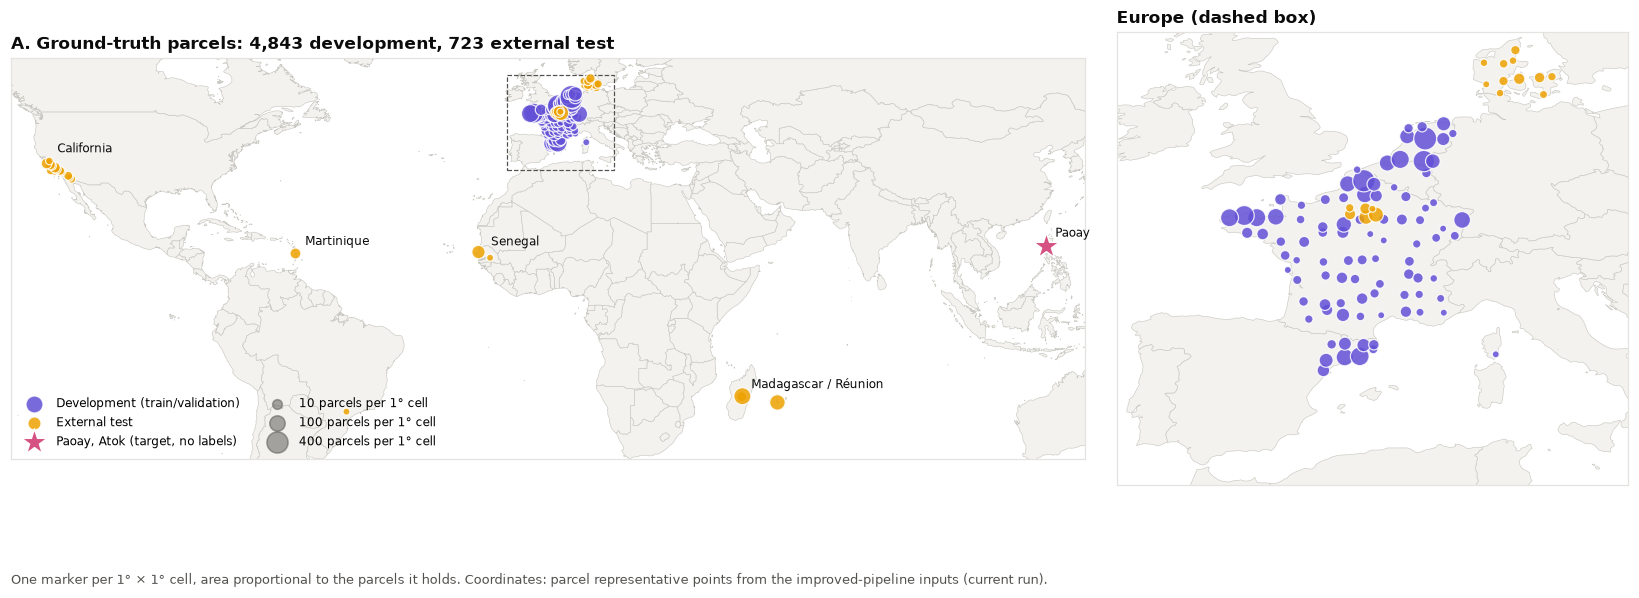

In [3]:
F.ground_truth_map(frame, S.world_countries(root)); plt.show()

### 5.2 Crop class distribution
Each source supplies only some crops: EuroCrops gives only carrot, FranceCrops mostly cabbage, Sen4AgriNet
carrot and potato. A model can therefore partly learn **which source a pixel comes from** instead of which
crop it is (source confounding). Class weights in training balance crops, parcels and label confidence.

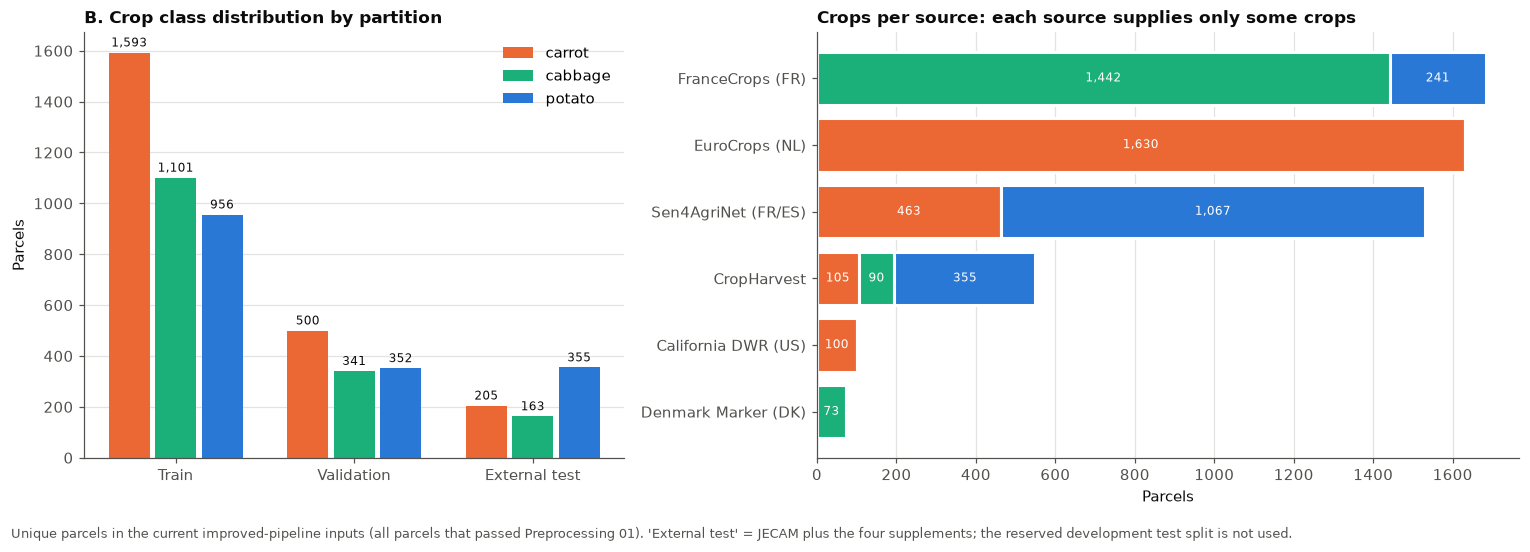

In [4]:
F.crop_distribution(frame); plt.show()

### 5.3 What the raw imagery looks like over Paoay
Sentinel-2 composites (false colour: vegetation is red). In the monsoon months most of the study area has
no clear observation in a half-month, which is why a method that needs four clear months fails here.

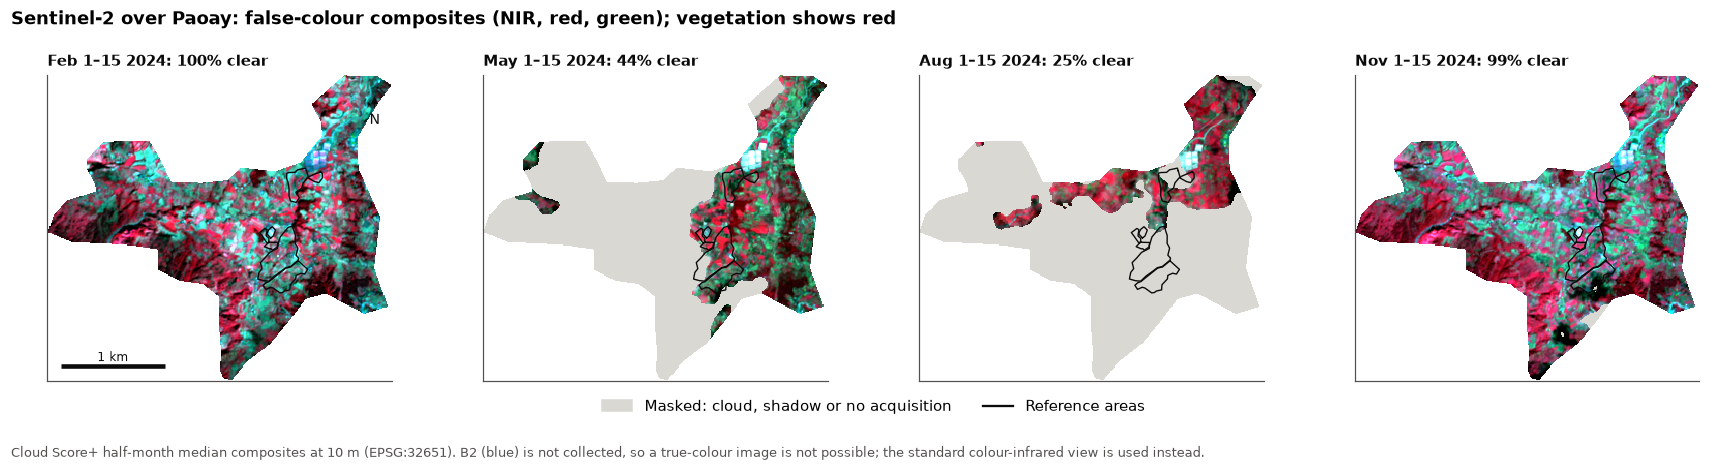

In [5]:
F.paoay_sentinel2(study); plt.show()

The same dates from Sentinel-1. Radar has no cloud gaps; bright areas are rough or vegetated, dark areas
smooth (water, bare compacted soil). On steep slopes, brightness also depends on how the slope faces the
radar, so terrain shows through. Speckle makes single pixels noisy, which is why the model uses smooth
annual curves rather than single dates.

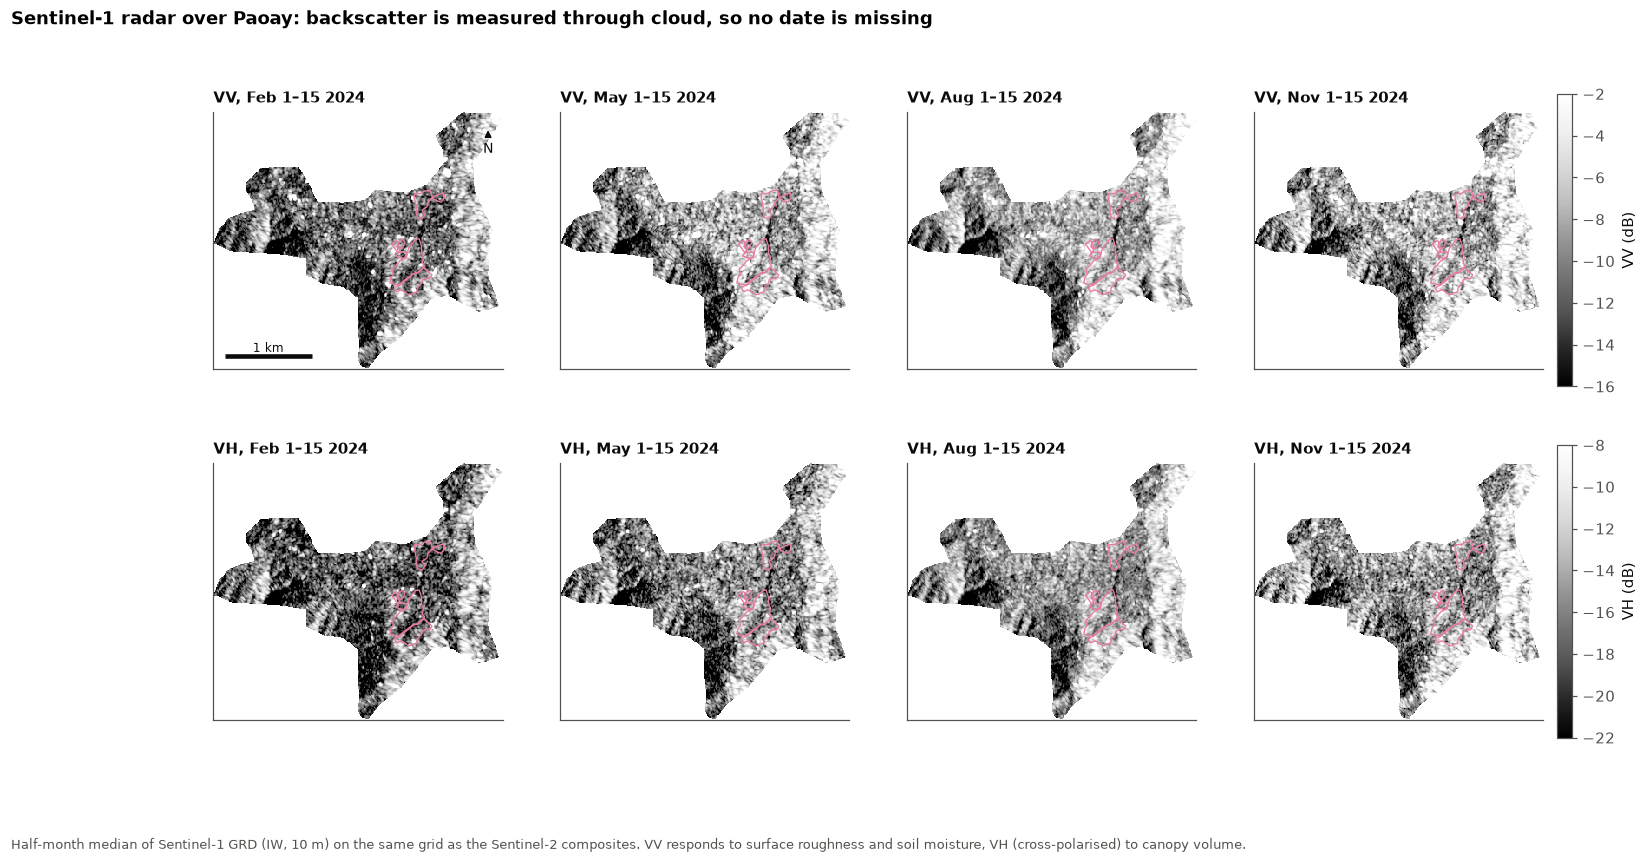

In [6]:
F.paoay_sentinel1(study); plt.show()

### 5.4 Temporal correspondence: do labels and imagery line up?
A label is only useful if the satellite sees the labelled crop growing in the labelled year. For a
stable random sample of parcels per group, each half-month is classed as **confirmed** (clear and inside
the detected crop cycle), **uncertain** (clear, but the parcel shows no crop cycle that year), **off-season**
or **unavailable** (no clear observation). The right panel shows how much of each crop cycle was actually
observed.

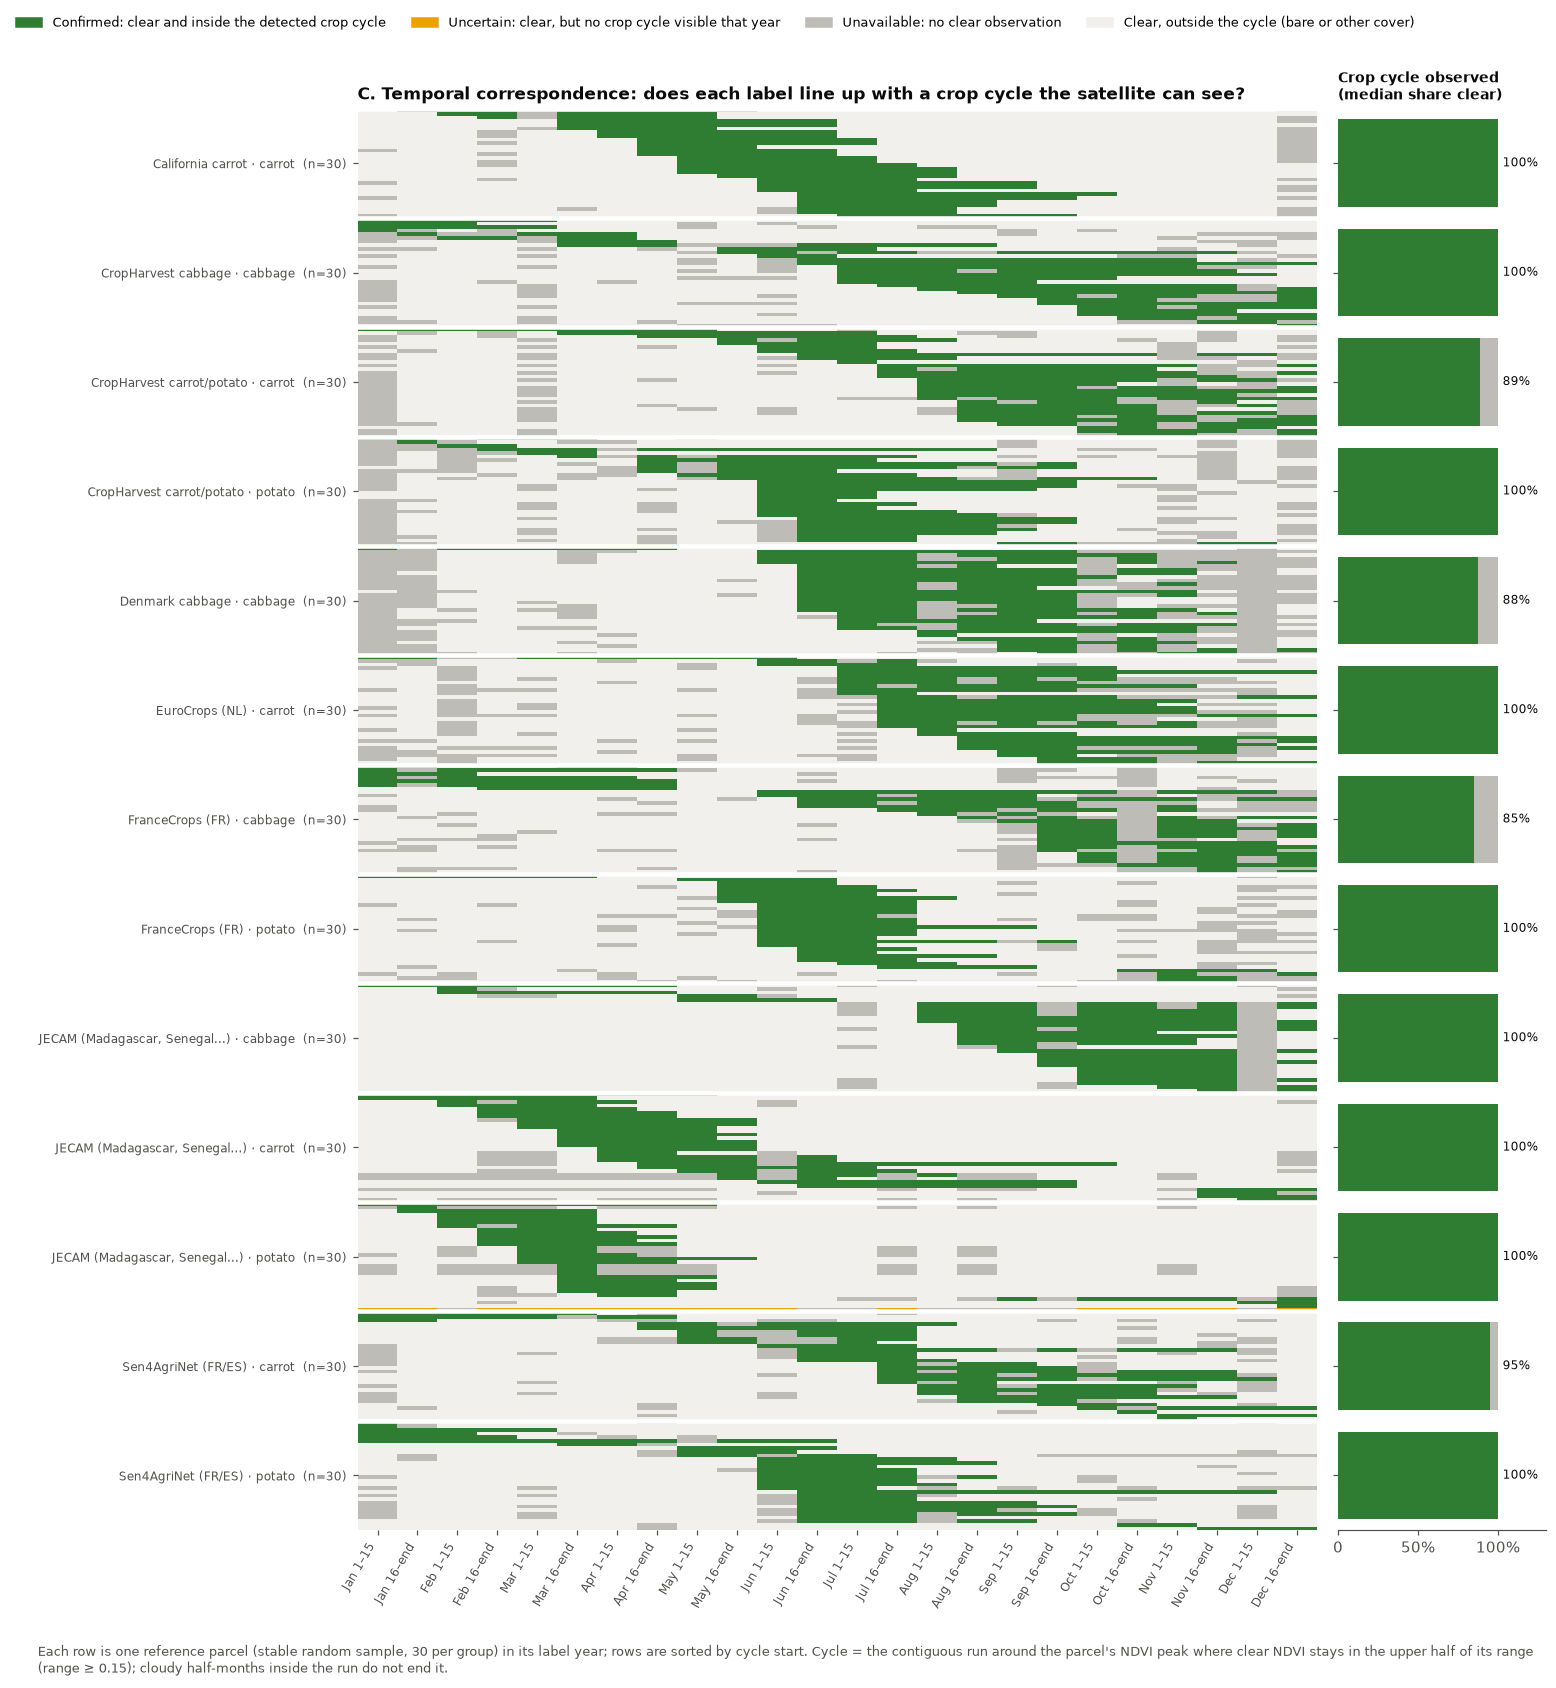

All 5,566 parcels: 99.8% show a crop cycle; 0.2% are clear but flat (label not visible).


In [7]:
groups, series, clear = M.parcel_series(rows, inputs["s2"], inputs["valid"])
meta = frame.drop_duplicates("partition_group").set_index("partition_group").loc[groups]
label = np.asarray(np.where(meta.partition == "test", meta.test_cohort.map(F.COHORT_NAMES),
                            meta.source_dataset.map(F.SOURCE_NAMES)) + " · " + meta.crop)
status = M.temporal_correspondence(series, clear)
keep = M.sample_per_group(label, groups, 30)
F.temporal_correspondence_heatmap(status[keep], label[keep]); plt.show()
cycle = (status == M.IN_SEASON).any(axis=1)
print(f"All {len(groups):,} parcels: {cycle.mean():.1%} show a crop cycle; "
      f"{(status == M.UNCERTAIN).any(axis=1).mean():.1%} are clear but flat (label not visible).")

Reading it: almost every labelled parcel shows a visible crop cycle in its label year, so the labels and the
imagery do correspond. The **timing** of the cycle varies widely, both within and between groups (the
staircases): carrot in the Netherlands peaks in late summer, JECAM carrot in the first half of the year. A
fixed May–Aug window catches some of these cycles and misses others, which motivates either a per-pixel
window (aligned) or features that do not depend on a window at all (harmonics).

## 6. Preprocessing (main pipeline Preprocessing 01, shared by both pipelines)

### 6.A Before and after cloud masking
One parcel composite from the current quality table that lost most of its pixels to cloud. Each pixel had
several acquisitions in the half-month; the mask removes those flagged as cloud or shadow and the composite
is built from what is left.

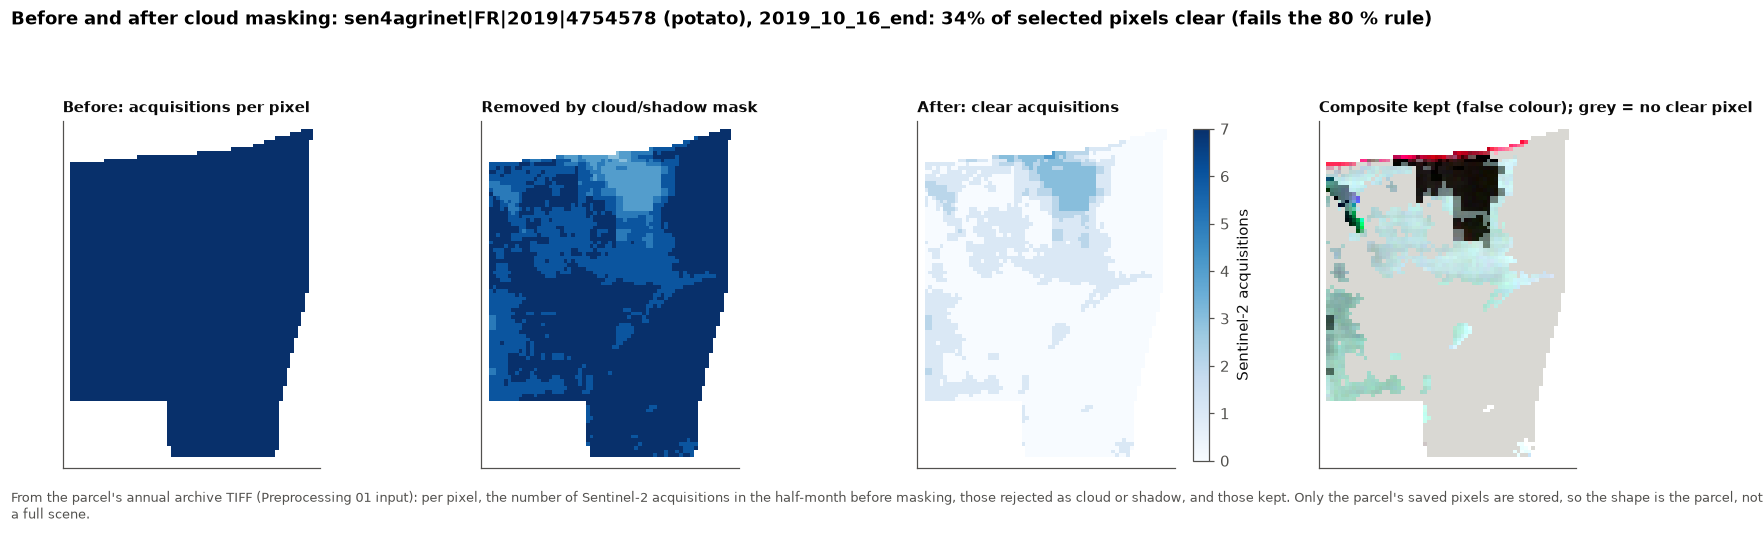

In [8]:
example, layers = F.pick_masking_example(quality, S.parcel_archive)
F.cloud_masking(layers, example["name"], example); plt.show()

### 6.B Valid-observation heatmap

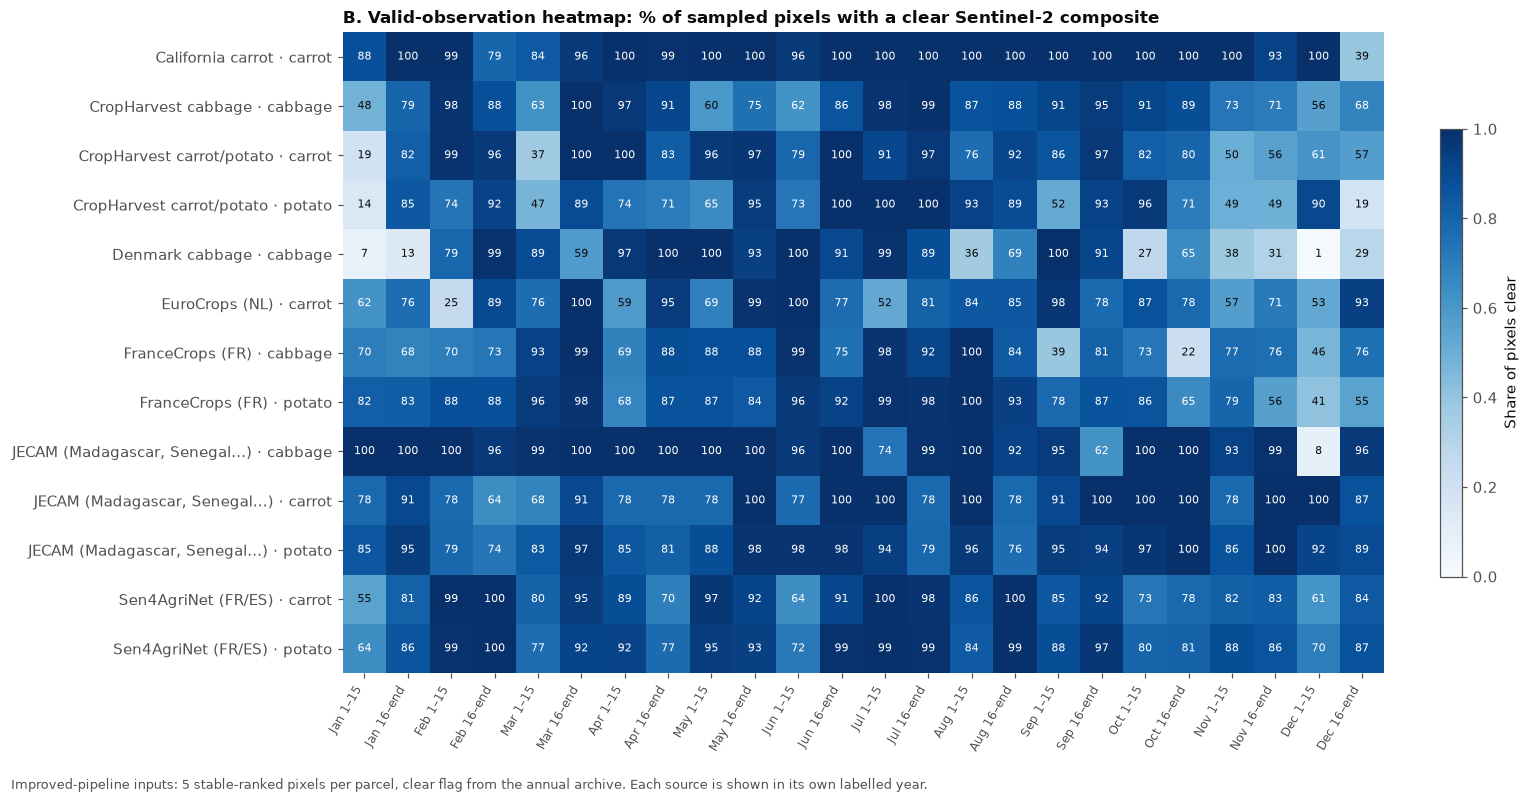

In [9]:
grouped = frame.assign(group=np.where(frame.partition == "test", frame.test_cohort.map(F.COHORT_NAMES),
                                      frame.source_dataset.map(F.SOURCE_NAMES)))
F.valid_observation_heatmap(M.valid_share(grouped, inputs["valid"], ("group", "crop"))); plt.show()

Winter half-months in Europe and Denmark are the cloudiest; JECAM sites are mostly clear in their dry
seasons. The external test sites are not harder because of cloud alone: the bigger problem is calendar and
climate (section 6.D).

### 6.C Usable coverage by interval
Top: share of parcel composites that pass the 80 % rule. Bottom: the same question for Paoay pixels in
2024, the year the maps use. The main pipeline's fixed window falls in Paoay's cloudiest months.

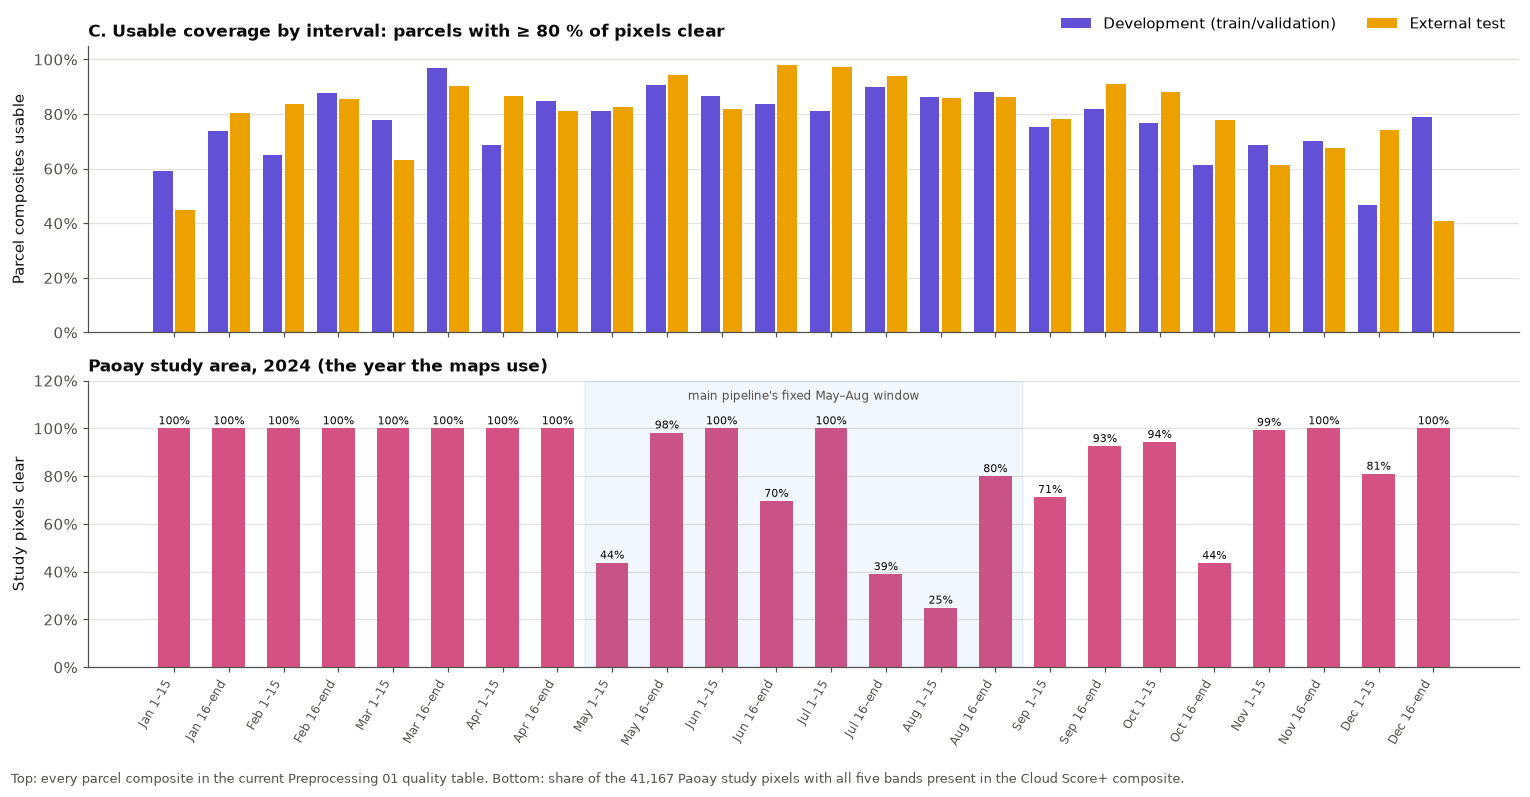

Paoay 2024: best 4-month window minimum clear share = 100%; May–Aug minimum = 25%


In [10]:
paoay_clear = np.isfinite(study["s2"]).all(axis=2).mean(axis=0)
F.usable_coverage(quality, rows, paoay_clear); plt.show()
four_month = [paoay_clear[b:b + 8].min() for b in range(17)]
print(f"Paoay 2024: best 4-month window minimum clear share = {max(four_month):.0%}; "
      f"May–Aug minimum = {paoay_clear[8:16].min():.0%}")

### 6.D Crop spectral signatures

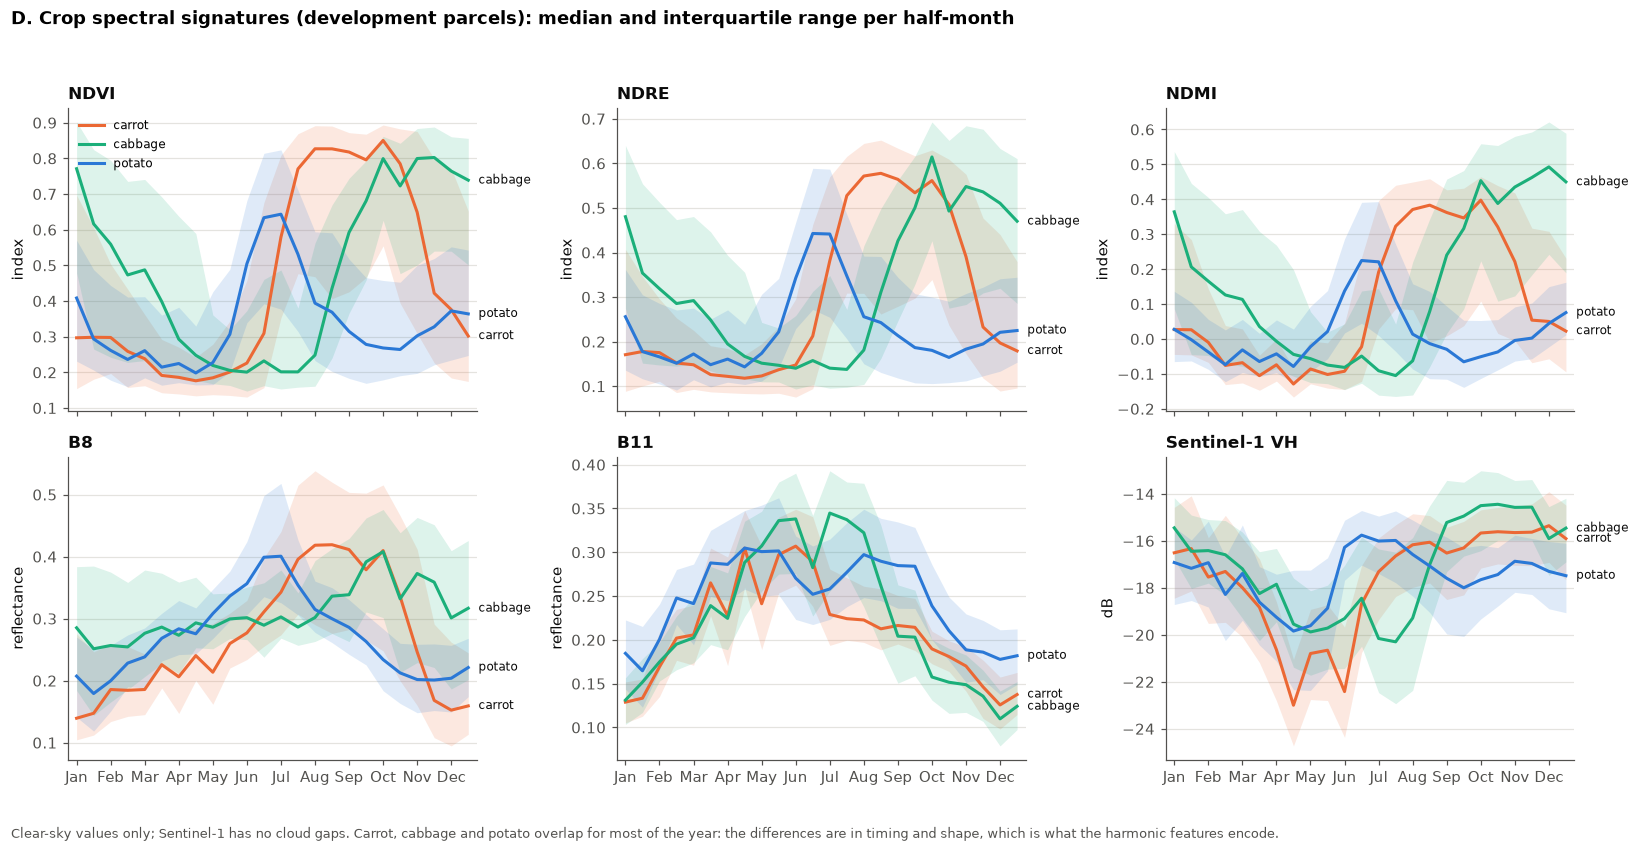

In [11]:
F.spectral_signatures(frame, inputs['s2'], inputs['valid'], inputs['s1']); plt.show()

The crops overlap in any single half-month but differ in **shape and timing**: cabbage stays green into
winter, carrot greens late and senesces in autumn, potato peaks early (June–July) in Europe. Moisture (NDMI)
and VH follow the same cycles. Those differences are learnable, but they are tied to European calendars:

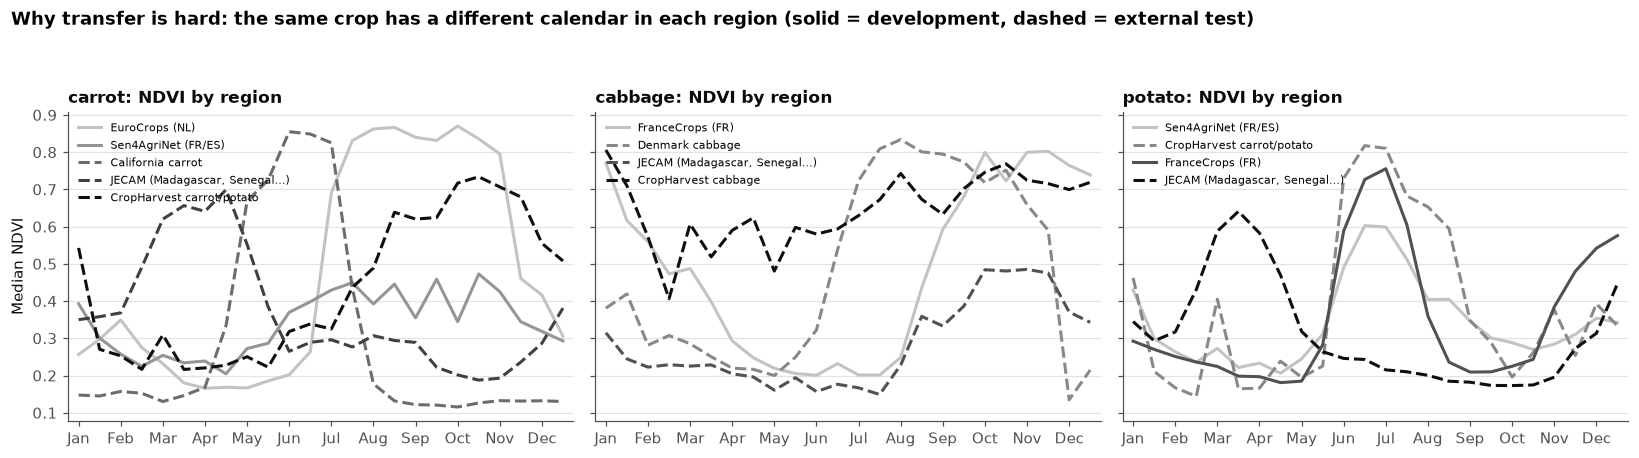

In [12]:
F.signature_shift(frame, inputs['s2'], inputs['valid']); plt.show()

The same crop has a different calendar in each region (dashed lines are external test populations). Any
feature that encodes *when* a crop greens up transfers poorly to a region with another calendar. This is
domain shift (Nyborg et al. 2022), and it is the main reason external scores are much lower than
validation scores.

## 7. Features: how one pixel's year becomes model inputs
- **Main pipeline (72 predictors):** the values of 5 bands + 4 indices in 8 consecutive half-months. All 8
  must be clear, or the pixel gets no prediction.
- **Improved pipeline (83 predictors):** for each of the 9 Sentinel-2 variables, a two-harmonic curve is fitted
  through every clear half-month of the year (at least 12 clear, no gap longer than 6), giving 7 terms
  (mean, amplitude and phase of the annual and half-year waves). Sentinel-1 adds VV and VH harmonics and two
  ratio summaries.

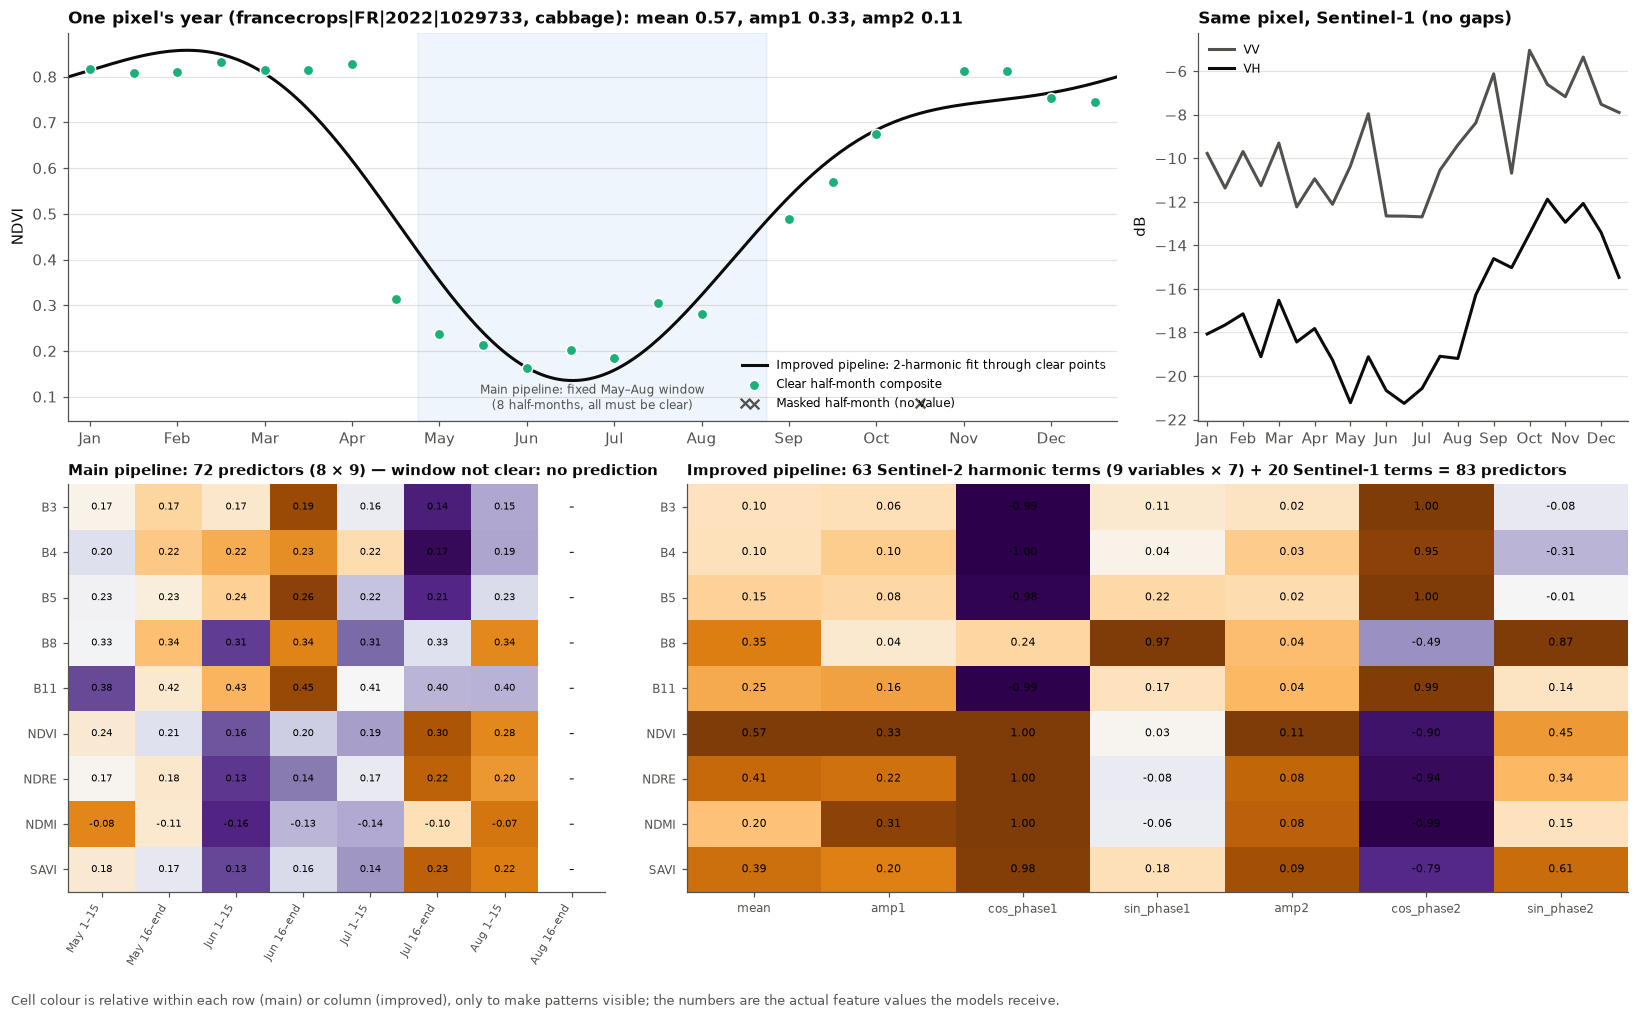

In [13]:
index = S.example_pixel(frame, inputs["valid"])
F.feature_anatomy(inputs["s2"][index], inputs["valid"][index], inputs["s1"][index],
                  f"{rows[index]['partition_group']}, {rows[index]['crop']}", model["info"]["feature_columns"]); plt.show()

This pixel shows the difference directly: one cloudy half-month in late August removes it from the main
pipeline's fixed window, while the harmonic curve still describes its whole year (greenness falling in
spring, the cabbage crop greening again from September).

## 8. The main (baseline) pipeline
`notebooks/` and `src/crop_pipeline/`, shared with the team.

1. **Collection:** half-month Sentinel-2 composites for every parcel (Earth Engine), with stable parcel IDs
   and locked partitions.
2. **Preprocessing 01:** cloud/shadow masking and the 80 % rule (section 6).
3. **Preprocessing 02:** a 4-month window per pixel: **fixed** (May–Aug) or **aligned** (green-up start).
4. **Preprocessing 03:** 72 predictors, up to 20 pixels per parcel, crop × parcel × label-confidence weights.
5. **Training:** Random Forest (1,000 trees) for four cohorts (fixed/aligned × full/matched sample), chosen on
   the validation partition, then frozen.
6. **Testing:** each external population scored once against the majority baseline.

It is a careful, leak-free design, and its validation macro-F1 is high (0.87 fixed, 0.77 aligned on
European validation parcels). The weakness shows only outside Europe, in section 10.

## 9. The improved pipeline and the experiments behind it
`experiments/improved_v1/` and `experiments/notebooks/improved_v1/`. It keeps the main pipeline's quality check,
locked partitions, training weights, Random Forest, confidence rule and single external test, and changes
three things, each motivated by an experiment:

| Experiment (notebooks) | Question | What it showed | Kept? |
|---|---|---|---|
| Tuning grid, spatial CV, seed stability (`tuning/01–03`) | Is the main pipeline just badly tuned? | Hyperparameters change validation by a few hundredths; the transfer gap is not a tuning problem | No change |
| Leave one source out (`transfer/02`) | Does the model learn sources instead of crops? | Recall collapses when a whole source is held out: source confounding | Select by dataset holdout |
| Fixed start-month sweep (`transfer/06`, `13`) | Is there a better fixed window? | The best European windows are 1–6 % clear in Paoay; the only clear window (Jan–Apr) is weakest in Europe | Drop windows |
| Harmonic features (`pilots/02`, `06`) | Can features tolerate gaps? | Every pixel scored; much better dataset-holdout score than the fixed window; JECAM mixed in the pilot | **Yes** |
| Sentinel-1 (`pilots/03`, `07`) | Does radar help? | Better dataset-holdout scores and no cloud gaps; no JECAM gain in the small pilot | **Yes** |
| Augmentation, source weights, anchor calibration, pairwise, climate matching, GMM clustering | Other fixes for transfer | No consistent gain | No |

The exploratory pilots ran on earlier data snapshots, so their exact numbers are not repeated here. The
selection experiment below is the current one: four candidate feature sets scored on the current
development data under three increasingly strict views. No test parcel is used.

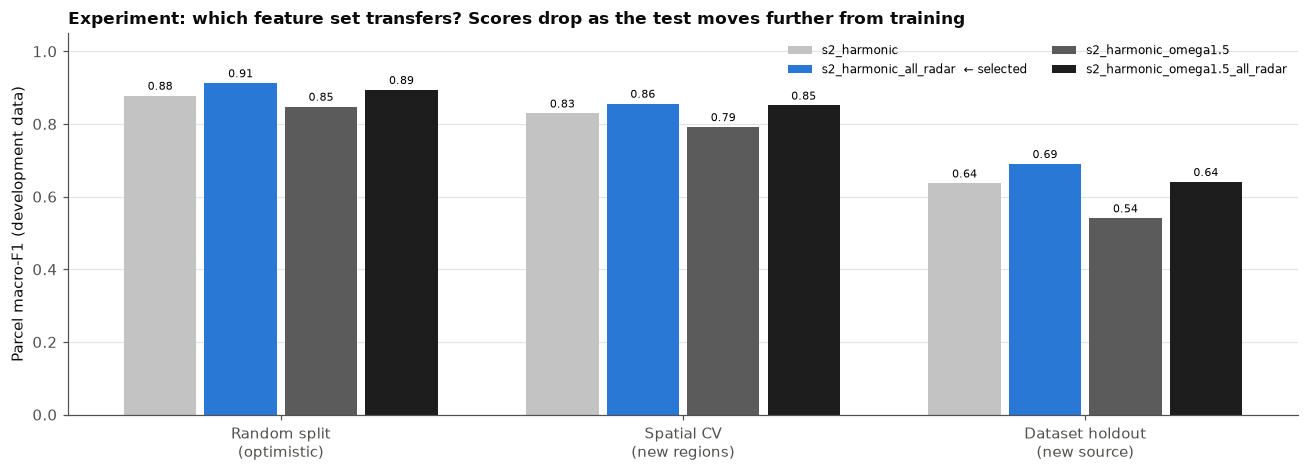

,random_split_macro_f1,spatial_cv_macro_f1,dataset_holdout_macro_f1
candidate,,,
s2_harmonic,0.878,0.829,0.637
s2_harmonic_all_radar,0.913,0.856,0.690
s2_harmonic_omega1.5,0.848,0.792,0.541
s2_harmonic_omega1.5_all_radar,0.894,0.851,0.641


In [14]:
F.selection_views(selection["scores"], selection["selection"]["selected"]); plt.show()
display(selection["scores"].groupby("candidate")[["random_split_macro_f1", "spatial_cv_macro_f1",
                                                  "dataset_holdout_macro_f1"]].mean().round(3))

Scores fall from random split to dataset holdout for every candidate: a model looks best when tested on
data like its training data. Adding Sentinel-1 helps most where it matters, on held-out datasets, so
`s2_harmonic_all_radar` is selected.

**Dataset variants.** `07_dataset_variants.ipynb` repeats selection and testing on the groupmate's parcels,
yours and both. It has not been run yet, so no variant result is shown here.

## 10. Results on the external test

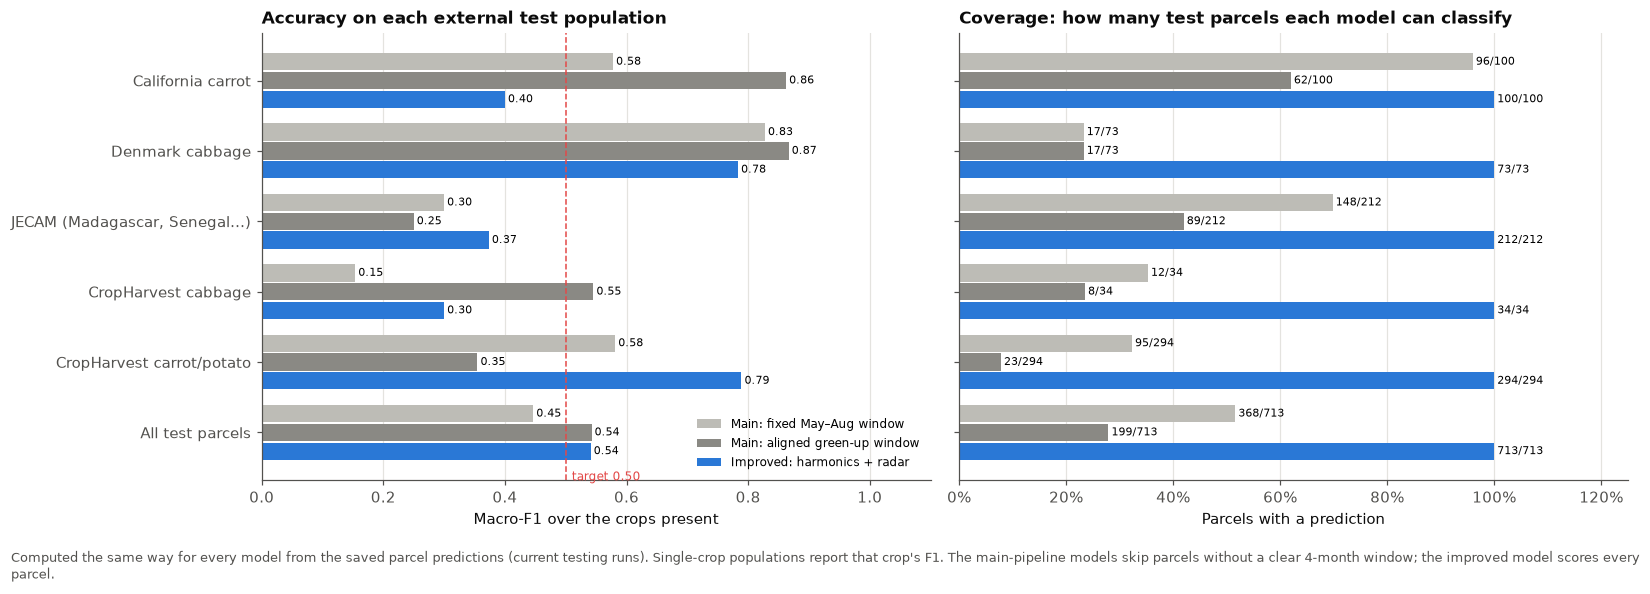

model,Improved: harmonics + radar,Main: aligned green-up window,Main: fixed May–Aug window
population,,,
california_dwr_carrot_2023_v1,0.400,0.862,0.578
combined,0.541,0.542,0.447
denmark_marker_cabbage_2023_v1,0.783,0.867,0.828
jecam,0.374,0.250,0.300
non_jecam_cabbage_supplement_v1,0.300,0.545,0.154
non_jecam_carrot_potato_supplement_v1,0.789,0.355,0.581


In [15]:
predictions = improved_test["predictions"]
totals = predictions.groupby("test_cohort").size().to_dict()
totals["combined"] = len(predictions)
records = []
for cohort, name in (("fixed_full", "Main: fixed May–Aug window"), ("aligned_full", "Main: aligned green-up window")):
    records += M.population_records(name, S.main_population_predictions(main, cohort), totals, F.CROPS)
records += M.population_records("Improved: harmonics + radar", predictions, totals, F.CROPS)
F.model_comparison(records); plt.show()
display(pd.DataFrame(records).pivot(index="population", columns="model", values="f1").round(3))

- **Coverage** is the clearest difference: the main models skip every parcel without a clear 4-month window
  (the aligned model scores 199 of 713), the improved model scores all of them.
- **Accuracy is mixed.** The improved model is better on JECAM and on the CropHarvest carrot/potato set,
  and equal on the combined pool while scoring every parcel. The main aligned model is better on the
  California carrot, Denmark cabbage and CropHarvest cabbage sets, but only on the subset of parcels it can
  score, which are the clearest and most European-like ones.
- No model reaches 0.50 for every crop on JECAM.

### 10.A Confusion matrices and 10.B per-crop precision, recall and F1 (JECAM)

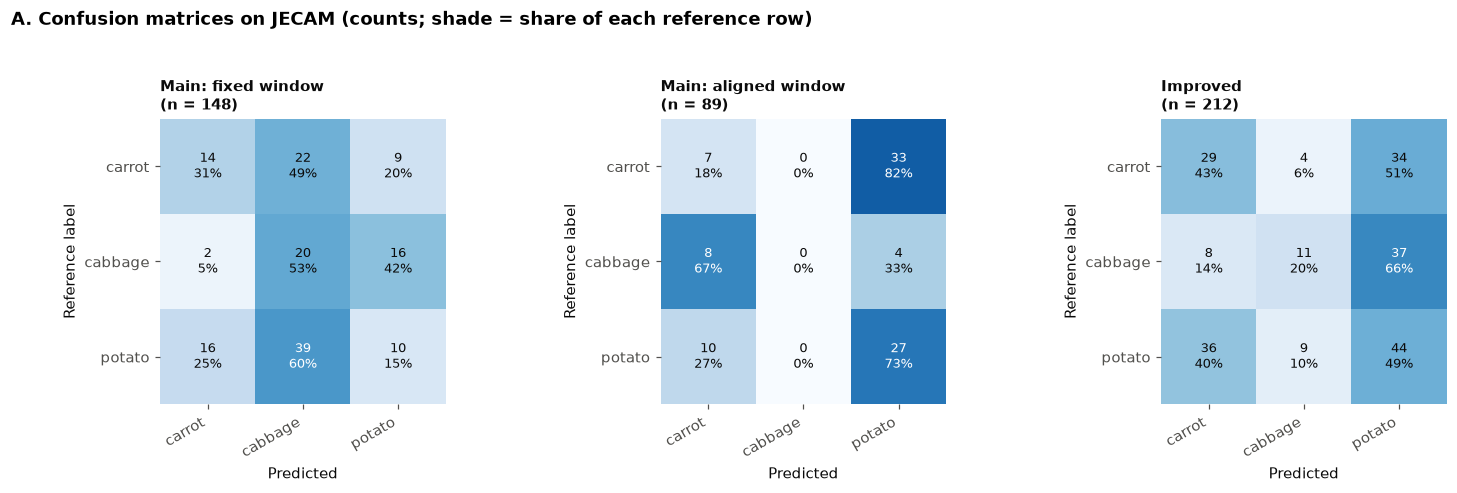

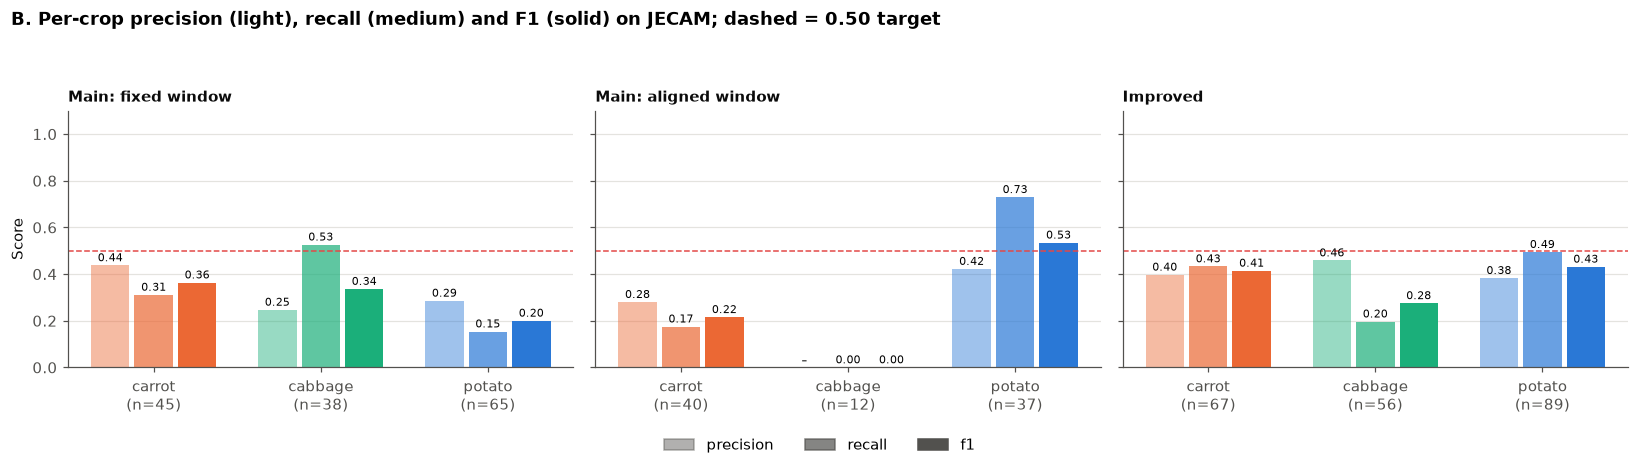

In [16]:
jecam = {"Main: fixed window": main["predictions"]["fixed_full"], "Main: aligned window": main["predictions"]["aligned_full"],
         "Improved": predictions[predictions.test_cohort == "jecam"]}
F.confusion_panels([(n, M.confusion(p.crop, p.prediction, list(F.CROPS))) for n, p in jecam.items()]); plt.show()
F.precision_recall_f1([(n, M.per_crop_scores(p.crop, p.prediction, F.CROPS)) for n, p in jecam.items()]); plt.show()

The improved model no longer ignores a crop (the aligned model never predicts cabbage), but on JECAM it still
confuses carrot and potato in both directions and calls two thirds of the cabbage parcels potato. That
cabbage F1 (about 0.28) is the weakest result and the main obstacle to the 0.50 target.

### 10.C Feature importance
A diagnostic of the frozen improved model on the external test pixels: all terms of one variable are
shuffled together and the drop in macro-F1 is measured. It is not used for any choice.

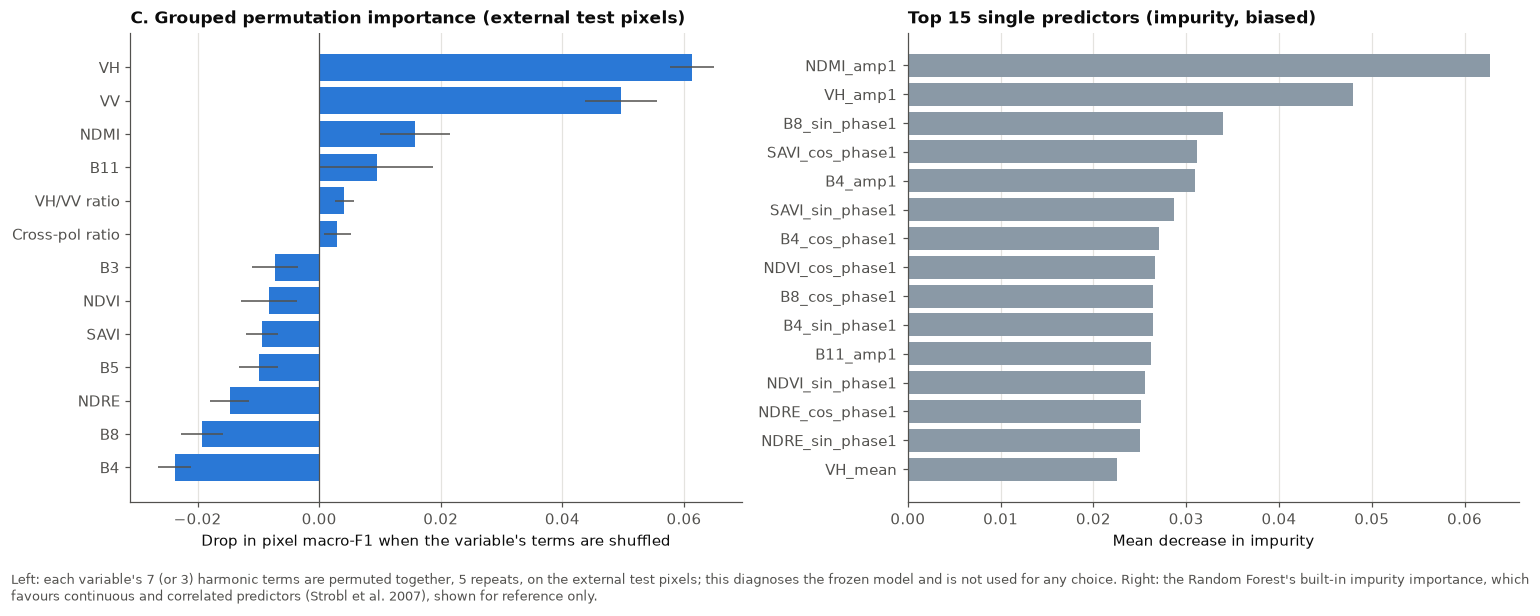

Pixel macro-F1 on external test pixels before shuffling: 0.566


In [17]:
X, ok, columns = workflow.CANDIDATES[model["candidate"]](inputs["s2"], inputs["valid"], inputs["s1"])
test_rows = (frame.partition == "test").to_numpy() & ok
importance, baseline_f1 = M.grouped_permutation_importance(model["model"], np.nan_to_num(X[test_rows]),
                                                           frame.crop.to_numpy()[test_rows], columns, repeats=5)
F.feature_importance(importance, pd.Series(model["model"].feature_importances_, index=columns)); plt.show()
print(f"Pixel macro-F1 on external test pixels before shuffling: {baseline_f1:.3f}")

Radar matters most on the external sites: shuffling VH or VV costs about 0.05–0.06 macro-F1. Several
Sentinel-2 variables have **negative** importance: shuffling them slightly *improves* external accuracy.
That means the model uses European-specific Sentinel-2 timing that misleads it elsewhere, which is the
domain shift of section 6.D seen from the model's side. It suggests trying a reduced or
timing-invariant Sentinel-2 feature set, tested by dataset holdout, never by the external test.

## 11. Maps: preliminary predictions in Paoay (2024)
Both maps use the same study boundary, grid and land-activity cropland mask, and the same confidence rule.
**Neither has been checked against fields on the ground.**

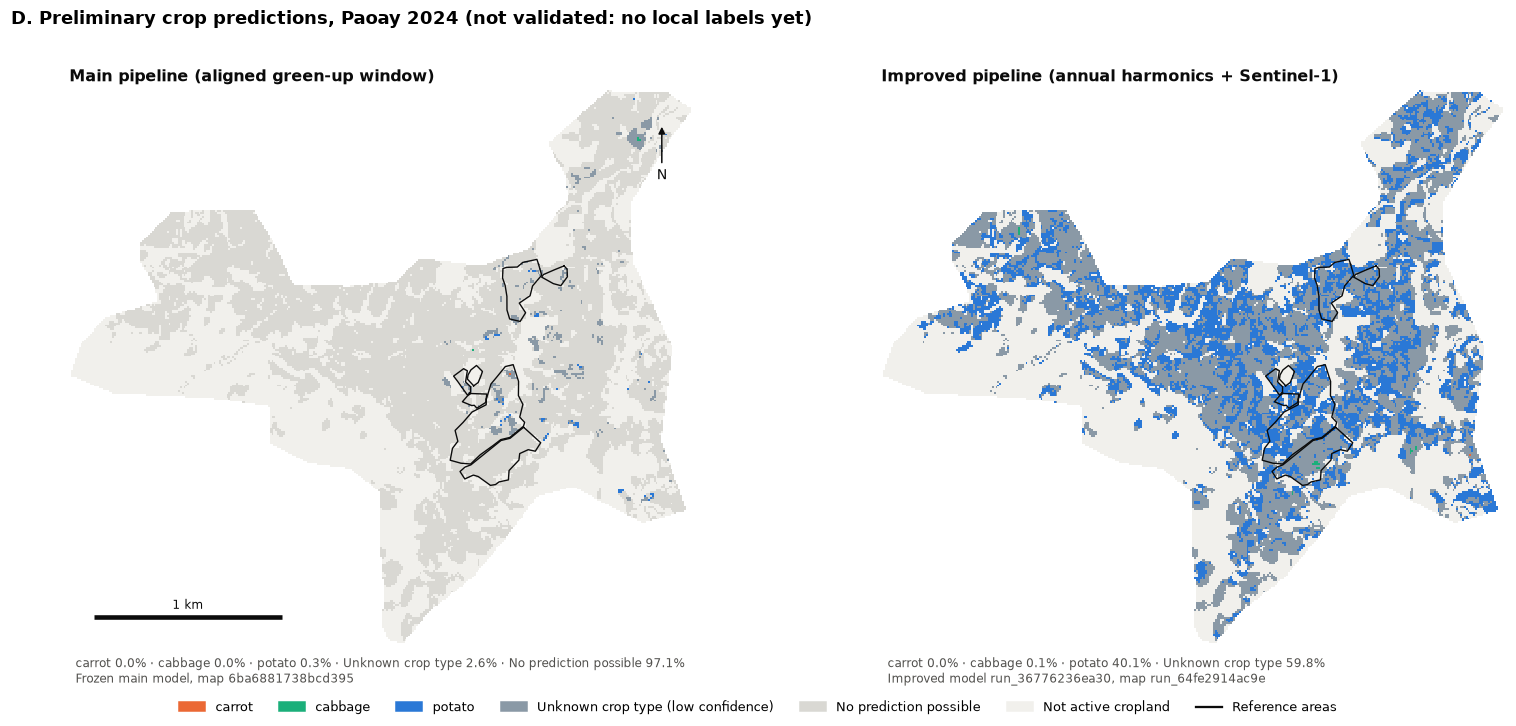

In [18]:
improved_names = M.class_names(paoay["codes"], M.IMPROVED_CODES, paoay["cropland"])
main_names = M.class_names(main_map["codes"], M.MAIN_ALIGNED_CODES, paoay["cropland"])
F.prediction_maps([("Main pipeline (aligned green-up window)", main_names, paoay["inside"],
                    f"Frozen main model, map {main_map['run'].name}"),
                   ("Improved pipeline (annual harmonics + Sentinel-1)", improved_names, paoay["inside"],
                    f"Improved model {model['run'].name}, map {paoay['run'].name}")],
                  study, "D. Preliminary crop predictions, Paoay 2024 (not validated: no local labels yet)"); plt.show()

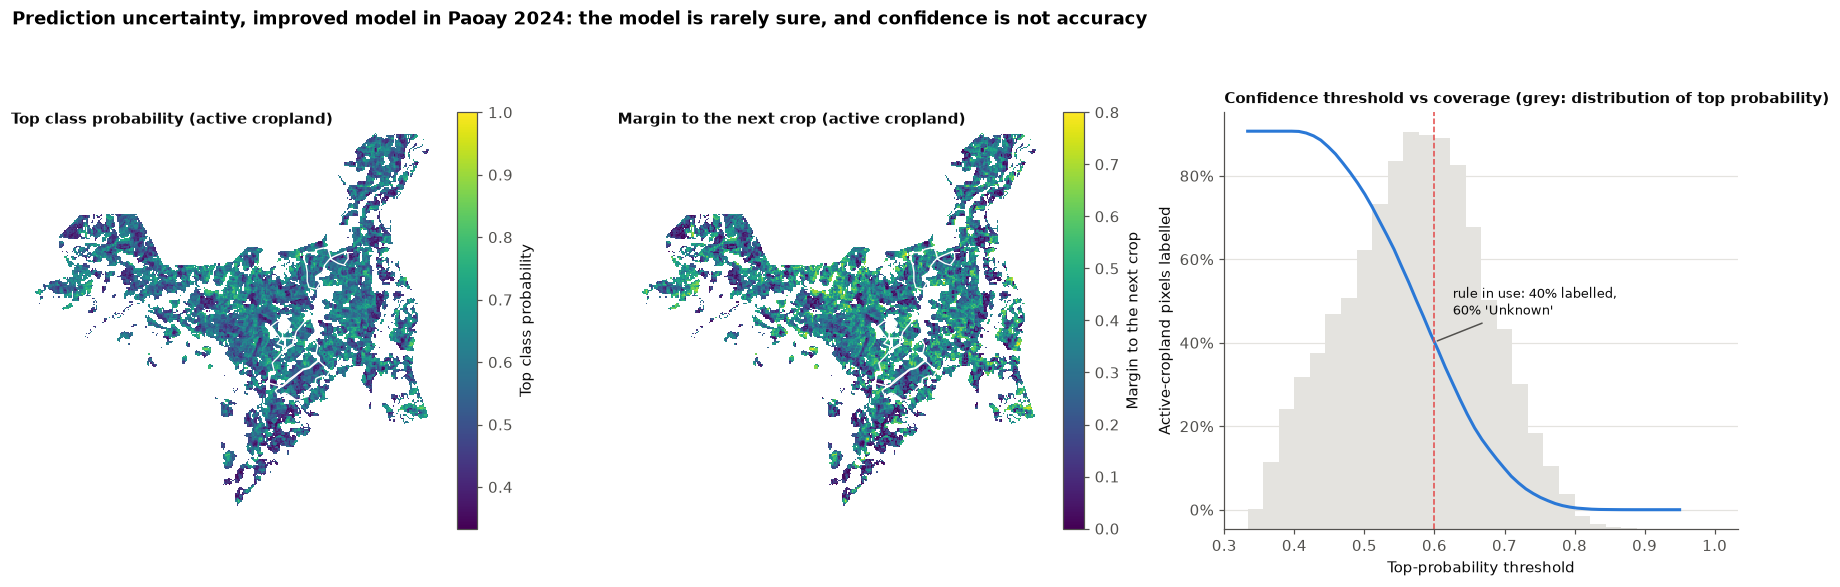

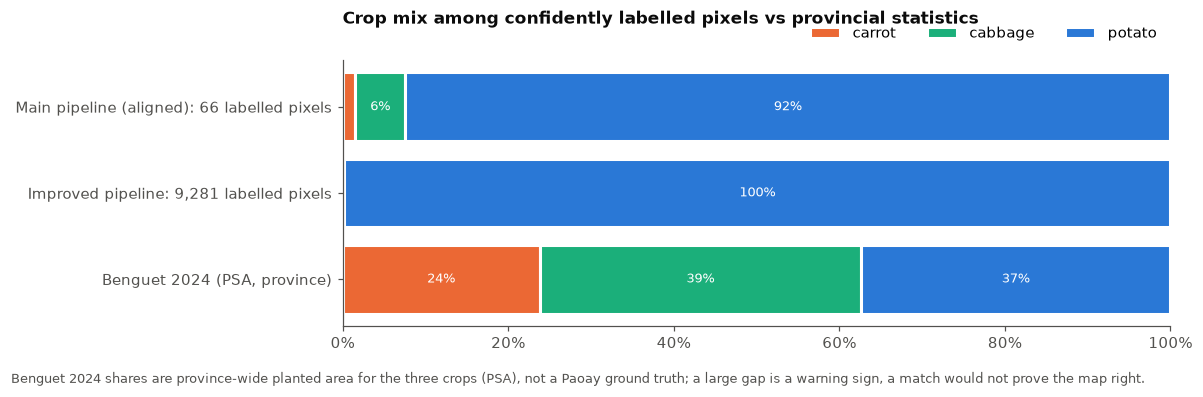

In [19]:
F.uncertainty_maps(paoay, study); plt.show()
shares = []
for name, names in (("Main pipeline (aligned)", main_names), ("Improved pipeline", improved_names)):
    values, count = M.confident_crop_shares(names[paoay["cropland"] & paoay["inside"]], F.CROPS)
    shares.append({"map": f"{name}: {count:,} labelled pixels", **values})
shares.append({"map": "Benguet 2024 (PSA, province)", **paoay["summary"]["benguet_2024_shares"]})
F.crop_shares(shares); plt.show()

What the maps show, and what they don't:
- The main pipeline can label almost nothing in Paoay: no green-up window qualifies, or the window is cloudy.
- The improved pipeline gives every pixel features, but only about 40 % of active cropland passes the
  confidence rule, and almost all of those pixels are called **potato**. Benguet statistics put potato near a
  third of the three crops' area. So the map is **biased toward potato**; the external-test confusion matrix
  shows the same tendency (cabbage predicted as potato).
- Confidence is not accuracy: the probability maps show where the model is unsure, not where it is right.
- The pattern is consistent with domain shift: the model has never seen a tropical highland crop calendar.

## 12. Limitations and next steps

**What the evidence supports**
- The data pipeline is leak-free and reproducible (locked partitions, receipts, single external test).
- Harmonic + radar features classify every parcel and pixel despite cloud, and transfer better to new
  datasets than fixed-window features on JECAM and CropHarvest carrot/potato.

**What it does not support**
- Any claim of crop-map accuracy in Paoay. There are no local labels yet.
- A firm ranking on single-crop populations, which have few parcels and only one crop.
- Small score differences: JECAM has 212 parcels and each model was run once.

**Next steps**
1. Collect field labels with the stratified field-visit plan (`improved/05`), then estimate map accuracy and
   areas with the Olofsson et al. (2014) design-based method.
2. Add local labels to training (the mixed-training experiment shows test-region data helps most) and test on
   held-out local fields.
3. Test timing-invariant or reduced Sentinel-2 features and source-balanced selection by dataset holdout.
4. Run `07_dataset_variants.ipynb` to see whether the extra development parcels change the results.